# Exploratory Data Analysis - Raw Household PV Generation (Belgium)

This notebook explores the raw 5-minute generation data downloaded from PVOutput,
resampled to **15-minute** resolution (the target resolution of the forecasting
model). It is organised around three questions raised during data preparation:

1. **Resampling** - what does averaging three 5-minute readings into one 15-minute
   value do, versus just sampling one reading?
2. **Start/stop times** - systems begin and end generation at different times of day.
3. **Seasonal daylight** - Belgian summer days are long, winter days short; how does
   that show up in the data?

> It auto-loads `pvoutput_raw/all_systems_5min.csv` and the metadata CSV if present.
> If not found, it generates realistic **demo** data so every cell still runs. The
> data cell prints which mode is active.


In [ ]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams["figure.dpi"] = 90

RAW_5MIN = Path("../pvoutput_raw/all_systems_5min.csv")
META_CSV = Path("../pvoutput_selection/systems_metadata.csv")

def make_demo():
    """Realistic synthetic 5-min data: seasonal day length, bell profiles,
    per-system start-time offsets, clouds. Mimics the real schema."""
    rng = np.random.default_rng(11)
    sysids = [f"{s}" for s in [1001,1002,1003,1004,1005,1006]]
    caps = dict(zip(sysids, [3.2, 4.5, 5.0, 6.2, 3.8, 5.5]))
    # orientation-driven offset (hours) applied to sunrise/sunset midpoint
    offs = dict(zip(sysids, [0.0, +1.2, -0.8, +0.4, +2.0, -0.3]))  # e.g. +ve = west-ish
    meta = pd.DataFrame({"system_id":[int(s) for s in sysids],
        "capacity_kwp":[caps[s] for s in sysids],
        "orientation":["S","SW","SE","S","W","SE"],
        "tilt_deg":[35,30,40,35,10,35],
        "latitude":[51.05,50.85,51.2,50.6,49.8,51.1],
        "longitude":[3.7,4.35,4.4,5.5,5.8,3.0]})
    rows = []
    days = pd.date_range("2024-01-01","2024-12-31",freq="D")
    for s in sysids:
        cap_w = caps[s]*1000
        for day in days:
            doy = day.dayofyear
            # daylight hours ~ 8 (winter) to 16.5 (summer) at ~51N
            daylen = 12.2 + 4.3*np.sin(2*np.pi*(doy-81)/365.25)
            noon = 13.6 + offs[s]*0.15          # solar noon ~13:36 local (CEST edge)
            sunrise = noon - daylen/2; sunset = noon + daylen/2
            cloud = np.clip(rng.beta(5,2)*rng.uniform(0.55,1.05), 0.05, 1.0)  # daily
            seas_amp = 0.45 + 0.55*np.sin(2*np.pi*(doy-81)/365.25)  # summer stronger
            t = sunrise
            cum = 0.0
            while t <= sunset:
                x = (t-sunrise)/max(daylen,1e-6)          # 0..1 across the day
                clear = np.sin(np.pi*x)**1.15             # bell
                minute_cloud = cloud*np.clip(1+rng.normal(0,0.18),0.2,1.3)
                p = max(0.0, cap_w*seas_amp*clear*minute_cloud)
                cum += p*(5/60.0)
                hh = int(t); mm = int(round((t-hh)*60))
                if mm==60: hh+=1; mm=0
                ts = pd.Timestamp(day.year,day.month,day.day,min(hh,23),mm,
                                  tz="Europe/Brussels")
                rows.append((int(s), ts.isoformat(), round(cum,0), round(p,0)))
                t += 5/60.0
    df = pd.DataFrame(rows, columns=["system_id","timestamp","energy_gen_wh","power_gen_w"])
    return df, meta

if RAW_5MIN.exists():
    df5 = pd.read_csv(RAW_5MIN)
    meta = pd.read_csv(META_CSV) if META_CSV.exists() else None
    MODE = "REAL DATA"
else:
    df5, meta = make_demo()
    MODE = "DEMO DATA (real files not found)"

df5["timestamp"] = pd.to_datetime(df5["timestamp"], utc=True).dt.tz_convert("Europe/Brussels")
df5 = df5.sort_values(["system_id","timestamp"]).reset_index(drop=True)
df5["date"] = df5["timestamp"].dt.date
df5["tod_h"] = df5["timestamp"].dt.hour + df5["timestamp"].dt.minute/60.0
df5["month"] = df5["timestamp"].dt.month
def season(m): return {12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
                       6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}[m]
df5["season"] = df5["month"].map(season)
print("Loaded:", MODE)
print(f"{df5['system_id'].nunique()} systems | {len(df5):,} 5-min rows | "
      f"{df5['timestamp'].min().date()} to {df5['timestamp'].max().date()}")
if meta is not None:
    cap_map = dict(zip(meta["system_id"], meta["capacity_kwp"]))
    df5["capacity_kwp"] = df5["system_id"].map(cap_map)
    df5["norm_power"] = df5["power_gen_w"]/(df5["capacity_kwp"]*1000)
df5.head()


Loaded: REAL DATA
34 systems | 3,818,001 5-min rows | 2024-04-01 to 2026-06-01


,system_id,timestamp,energy_gen_wh,efficiency,power_gen_w,power_avg_w,normalised_output,energy_cons_wh,power_cons_w,temperature_c,...,v9,v10,v11,v12,date,tod_h,month,season,capacity_kwp,norm_power
0,2358,2024-04-01 07:35:00+02:00,0.0,0.000,0.0,NaN,NaN,NaN,NaN,33.4,...,NaN,NaN,NaN,NaN,2024-04-01,7.583333,4,Spring,3.15,0.000000
1,2358,2024-04-01 07:40:00+02:00,2.0,0.001,24.0,24.0,0.008,NaN,NaN,34.6,...,NaN,NaN,NaN,NaN,2024-04-01,7.666667,4,Spring,3.15,0.007619
2,2358,2024-04-01 07:45:00+02:00,4.0,0.001,24.0,24.0,0.008,NaN,NaN,35.1,...,NaN,NaN,NaN,NaN,2024-04-01,7.750000,4,Spring,3.15,0.007619
3,2358,2024-04-01 07:50:00+02:00,4.0,0.001,0.0,0.0,0.000,NaN,NaN,35.4,...,NaN,NaN,NaN,NaN,2024-04-01,7.833333,4,Spring,3.15,0.000000
4,2358,2024-04-01 07:55:00+02:00,4.0,0.001,24.0,0.0,0.000,NaN,NaN,35.6,...,NaN,NaN,NaN,NaN,2024-04-01,7.916667,4,Spring,3.15,0.007619


In [4]:
import pandas as pd
# d = pd.read_csv("../pvoutput_raw/all_systems_daily.csv", usecols=["timestamp"])
df = pd.read_csv("../pvoutput_raw/all_systems_5min.csv")
systems_ids = df["system_id"].unique()
for system_id in systems_ids:
    d = df[df["system_id"] == system_id]
    
    ts = pd.to_datetime(d["timestamp"], utc=True).sort_values()
    print(f"For system {system_id} median gap:", ts.diff().median())   # ~5 min, ~10 min, or ~15 min

For system 33949 median gap: 0 days 00:05:00
For system 17340 median gap: 0 days 00:05:00
For system 94340 median gap: 0 days 00:05:00
For system 23778 median gap: 0 days 00:05:00
For system 67739 median gap: 0 days 00:15:00
For system 16111 median gap: 0 days 00:15:00
For system 94362 median gap: 0 days 00:05:00
For system 100651 median gap: 0 days 00:15:00
For system 90841 median gap: 0 days 00:05:00
For system 69695 median gap: 0 days 00:05:00
For system 83696 median gap: 0 days 00:15:00
For system 66168 median gap: 0 days 00:05:00
For system 2358 median gap: 0 days 00:05:00
For system 8983 median gap: 0 days 00:05:00
For system 9524 median gap: 0 days 00:05:00
For system 97042 median gap: 0 days 00:05:00
For system 78530 median gap: 0 days 00:15:00
For system 81702 median gap: 0 days 00:05:00
For system 56799 median gap: 0 days 00:15:00
For system 75975 median gap: 0 days 00:05:00
For system 104044 median gap: 0 days 00:05:00
For system 46190 median gap: 0 days 00:05:00
For system 

## 1. Resampling: 5-minute -> 15-minute

We aggregate every three 5-minute **power** readings into one 15-minute value by
**averaging**. The plot below compares, for one clear system-day, the raw 5-minute
signal, the 15-minute average, and the alternative of *sampling* one reading per
15 minutes. Averaging tracks the true signal; sampling can land on an unrepresentative
instant and throws away two-thirds of the information.

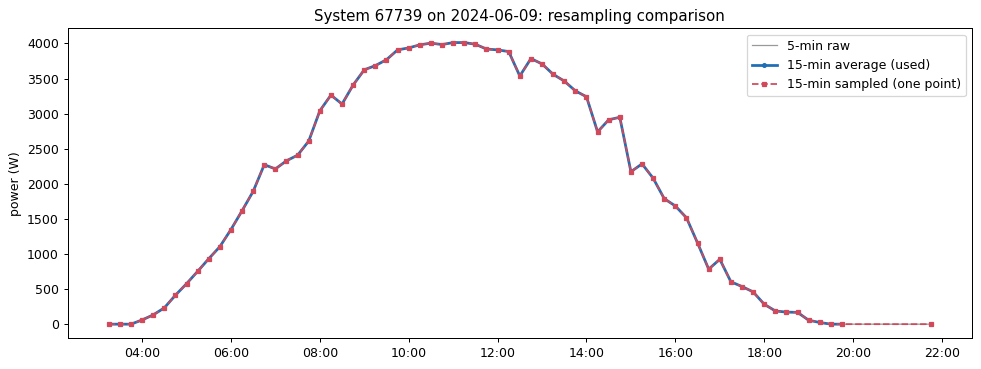

Notice where the dashed (sampled) line diverges from the blue (averaged) line - those are moments the single sampled reading misrepresents the 15-min block.


In [2]:
# resample power to 15-min (mean) per system
def resample_15(d):
    out = (d.set_index("timestamp").groupby("system_id")["power_gen_w"]
             .resample("15min").mean().reset_index())
    return out
df15 = resample_15(df5)
df15["date"] = df15["timestamp"].dt.date
df15["tod_h"] = df15["timestamp"].dt.hour + df15["timestamp"].dt.minute/60.0
df15["month"] = df15["timestamp"].dt.month
df15["season"] = df15["month"].map(season)
if meta is not None:
    df15["capacity_kwp"] = df15["system_id"].map(cap_map)
    df15["norm_power"] = df15["power_gen_w"]/(df15["capacity_kwp"]*1000)

# pick one system + one day with good sun
sid = df5["system_id"].iloc[len(df5)//2]
daily_e = df5.groupby(["system_id","date"])["energy_gen_wh"].max()
best_day = daily_e[sid].idxmax()
d5 = df5[(df5.system_id==sid)&(df5.date==best_day)]
d15 = df15[(df15.system_id==sid)&(df15.date==best_day)]
samp = d5[d5["timestamp"].dt.minute%15==0]   # "sample one per 15 min"

fig, ax = plt.subplots(figsize=(11,4.2))
ax.plot(d5["timestamp"], d5["power_gen_w"], color="0.6", lw=1, label="5-min raw")
ax.plot(d15["timestamp"], d15["power_gen_w"], color="#1f6fb5", lw=2.2, marker="o", ms=3, label="15-min average (used)")
ax.plot(samp["timestamp"], samp["power_gen_w"], color="#d1495b", lw=1.4, ls="--", marker="s", ms=3, label="15-min sampled (one point)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_ylabel("power (W)"); ax.set_title(f"System {sid} on {best_day}: resampling comparison")
ax.legend(); plt.tight_layout(); plt.show()
print("Notice where the dashed (sampled) line diverges from the blue (averaged) line "
      "- those are moments the single sampled reading misrepresents the 15-min block.")


## 2. The typical daily generation profile

Averaging every system and day onto a common time-of-day axis gives the characteristic
solar “bell”. Using **capacity-normalised** power (output as a fraction of each
system’s rated size) lets differently-sized homes be averaged together fairly.

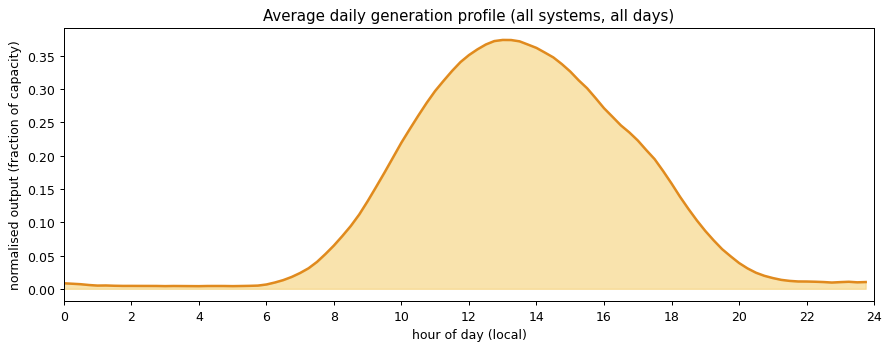

In [3]:
ycol = "norm_power" if meta is not None else "power_gen_w"
ylab = "normalised output (fraction of capacity)" if meta is not None else "power (W)"
prof = df15.groupby(df15["tod_h"])[ycol].mean()
fig, ax = plt.subplots(figsize=(10,4))
ax.fill_between(prof.index, prof.values, color="#f4c95d", alpha=0.5)
ax.plot(prof.index, prof.values, color="#e08a1e", lw=2)
ax.set_xlabel("hour of day (local)"); ax.set_ylabel(ylab)
ax.set_title("Average daily generation profile (all systems, all days)")
ax.set_xlim(0,24); ax.set_xticks(range(0,25,2)); plt.tight_layout(); plt.show()


## 3. Systems start and stop at different times (Point 2)

Each system has its own daily *generating window*. Differences arise from orientation
(west-facing roofs peak and end later), shading, and location. The chart shows, per
system, the median time of first and last meaningful generation - the spread is exactly
why every system must later be aligned onto one common time grid rather than trusting
each system’s own reporting hours.

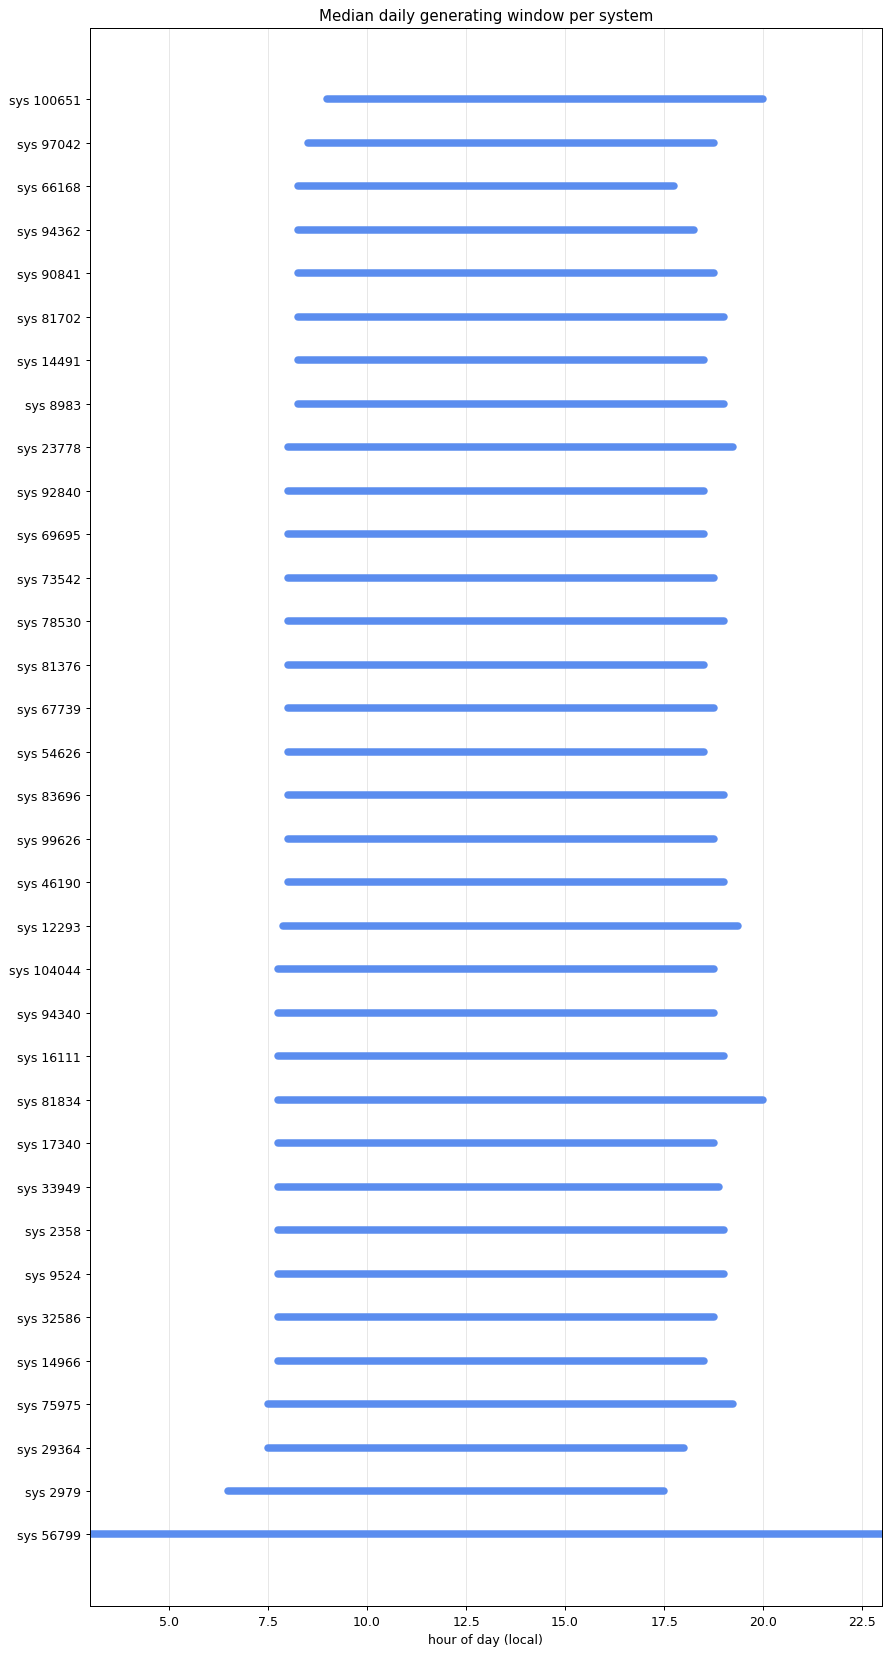

Each bar = one system's typical sunrise-to-sunset generating window. The horizontal offsets are the different start/stop times you noticed.


In [4]:
THRESH_FRAC = 0.02  # "generating" = >2% of capacity (or >20W if no capacity)
d = df15.copy()
if meta is not None:
    d["gen"] = d["norm_power"] > THRESH_FRAC
else:
    d["gen"] = d["power_gen_w"] > 20
gen = d[d["gen"]]
first = gen.groupby(["system_id","date"])["tod_h"].min().groupby("system_id").median()
last  = gen.groupby(["system_id","date"])["tod_h"].max().groupby("system_id").median()
order = first.sort_values().index
fig, ax = plt.subplots(figsize=(10, 0.5*len(order)+1.5))
for i, s in enumerate(order):
    ax.plot([first[s], last[s]], [i, i], lw=6, color="#5b8def", solid_capstyle="round")
ax.set_yticks(range(len(order))); ax.set_yticklabels([f"sys {s}" for s in order])
ax.set_xlabel("hour of day (local)"); ax.set_title("Median daily generating window per system")
ax.set_xlim(3,23); ax.grid(axis="x", alpha=0.3); plt.tight_layout(); plt.show()
print("Each bar = one system's typical sunrise-to-sunset generating window. "
      "The horizontal offsets are the different start/stop times you noticed.")


In [6]:
import pandas as pd
five = set(pd.read_csv("../pvoutput_raw/all_systems_5min.csv", usecols=["system_id"])["system_id"].unique())
short = set(pd.read_csv("../pvoutput_selection/shortlist_final.csv")["system_id"])
print("missing from 5-min:", sorted(short - five))

missing from 5-min: [58467]


## 4. Long summer days, short winter days (Point 3)

Two views of Belgium’s strong seasonal daylight cycle. First, the average generation
profile by season: summer is both **taller** (stronger sun) and **wider** (longer day);
winter is short and weak. Second, the average length of the daily generating window by
month, which traces the summer peak directly.

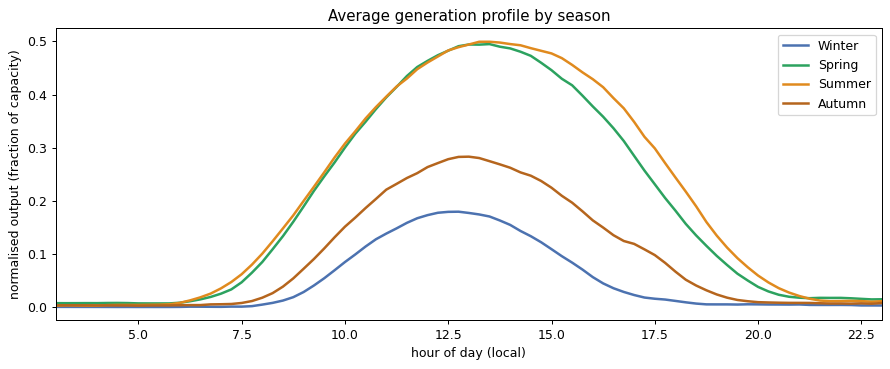

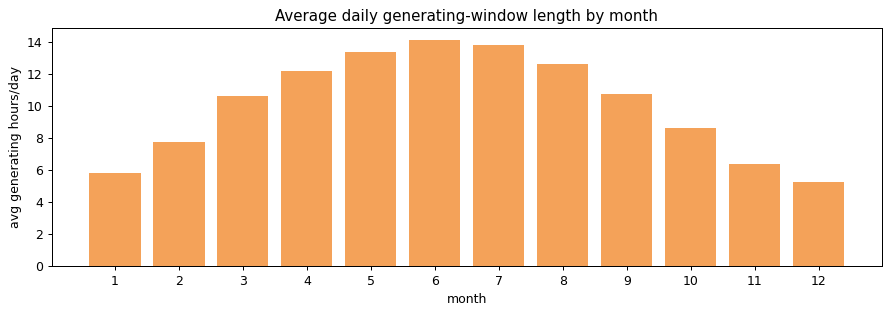

In [7]:
# seasonal average profiles
fig, ax = plt.subplots(figsize=(10,4.2))
colors = {"Winter":"#4c72b0","Spring":"#2ca25f","Summer":"#e08a1e","Autumn":"#b5651d"}
for seas in ["Winter","Spring","Summer","Autumn"]:
    sub = df15[df15.season==seas]
    if len(sub):
        p = sub.groupby("tod_h")[ycol].mean()
        ax.plot(p.index, p.values, label=seas, color=colors[seas], lw=2)
ax.set_xlabel("hour of day (local)"); ax.set_ylabel(ylab)
ax.set_title("Average generation profile by season"); ax.set_xlim(3,23)
ax.legend(); plt.tight_layout(); plt.show()

# daily generating-window length by month
dl = gen.groupby(["system_id","date"]).agg(first=("tod_h","min"), last=("tod_h","max"))
dl["hours"] = dl["last"] - dl["first"]
dl = dl.reset_index()
dl["month"] = pd.to_datetime(dl["date"]).dt.month
mlen = dl.groupby("month")["hours"].mean()
fig, ax = plt.subplots(figsize=(10,3.6))
ax.bar(mlen.index, mlen.values, color="#f4a259")
ax.set_xticks(range(1,13)); ax.set_xlabel("month")
ax.set_ylabel("avg generating hours/day")
ax.set_title("Average daily generating-window length by month")
plt.tight_layout(); plt.show()


## 5. Seasonal energy production

The monthly average of daily energy generated summarises the seasonal cycle in a single
curve - the quantity a household actually cares about. Daily energy is taken as the peak
of the cumulative daily energy counter (which resets each morning).

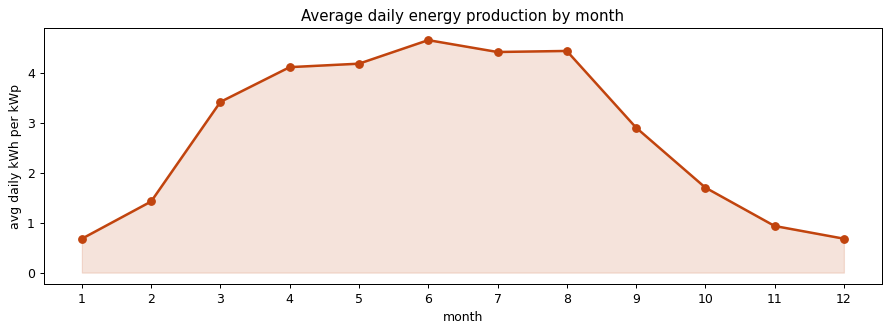

Summer months produce several times more per day than winter - the core seasonal challenge for a Belgian forecasting model.


In [7]:
daily_energy = df5.groupby(["system_id","date"])["energy_gen_wh"].max().reset_index()
daily_energy["month"] = pd.to_datetime(daily_energy["date"]).dt.month
if meta is not None:
    daily_energy["capacity_kwp"] = daily_energy["system_id"].map(cap_map)
    daily_energy["kwh_per_kwp"] = (daily_energy["energy_gen_wh"]/1000)/daily_energy["capacity_kwp"]
    m = daily_energy.groupby("month")["kwh_per_kwp"].mean(); ylab2 = "avg daily kWh per kWp"
else:
    daily_energy["kwh"] = daily_energy["energy_gen_wh"]/1000
    m = daily_energy.groupby("month")["kwh"].mean(); ylab2 = "avg daily kWh"
fig, ax = plt.subplots(figsize=(10,3.8))
ax.plot(m.index, m.values, marker="o", color="#c1440e", lw=2)
ax.fill_between(m.index, m.values, alpha=0.15, color="#c1440e")
ax.set_xticks(range(1,13)); ax.set_xlabel("month"); ax.set_ylabel(ylab2)
ax.set_title("Average daily energy production by month"); plt.tight_layout(); plt.show()
print("Summer months produce several times more per day than winter - the core "
      "seasonal challenge for a Belgian forecasting model.")


## 6. Data coverage and completeness

Before modelling, it is worth seeing how many days of data each system actually has.
Gaps and short histories were already screened during selection, but this confirms the
final coverage and highlights any system that may need extra care.

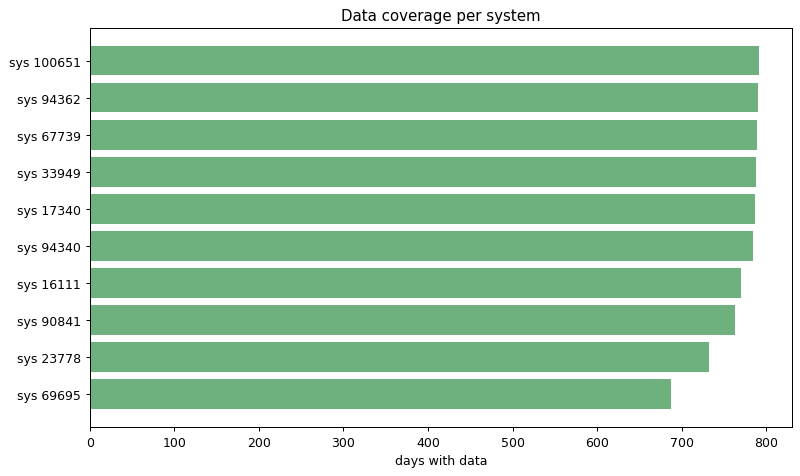

Total unique days in dataset: 791


In [8]:
days_per = df5.groupby("system_id")["date"].nunique().sort_values()
fig, ax = plt.subplots(figsize=(9, 0.42*len(days_per)+1.2))
ax.barh([f"sys {s}" for s in days_per.index], days_per.values, color="#6fb07f")
ax.set_xlabel("days with data"); ax.set_title("Data coverage per system")
plt.tight_layout(); plt.show()
print("Total unique days in dataset:", df5["date"].nunique())


## 7. Fleet characteristics

Finally, the spread of system sizes and performance across the sample. A range of
capacities and a healthy specific-yield distribution indicate a diverse but sound set of
homes.

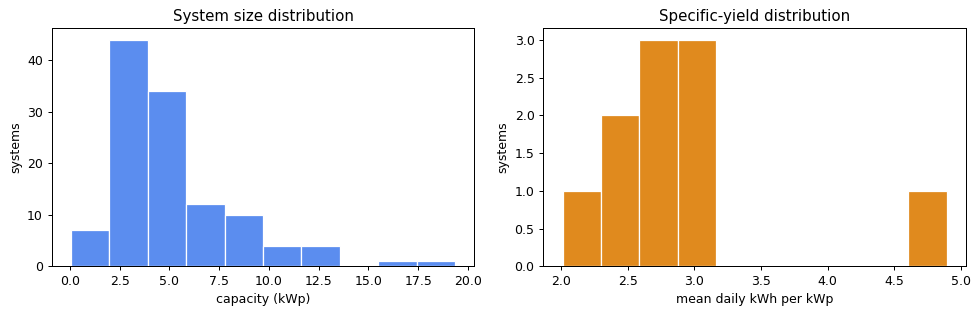

In [9]:
if meta is not None:
    sy = daily_energy.groupby("system_id")["kwh_per_kwp"].mean()
    fig, axes = plt.subplots(1,2, figsize=(11,3.6))
    axes[0].hist(meta["capacity_kwp"].dropna(), bins=10, color="#5b8def", edgecolor="white")
    axes[0].set_xlabel("capacity (kWp)"); axes[0].set_ylabel("systems")
    axes[0].set_title("System size distribution")
    axes[1].hist(sy.values, bins=10, color="#e08a1e", edgecolor="white")
    axes[1].set_xlabel("mean daily kWh per kWp"); axes[1].set_ylabel("systems")
    axes[1].set_title("Specific-yield distribution")
    plt.tight_layout(); plt.show()
else:
    print("Metadata not loaded - skipping fleet characteristics.")


## 8. Summary of findings

- **Resampling.** Averaging three 5-minute readings into each 15-minute value preserves
  the real short-term variability that single-point sampling would discard - important
  under Belgium’s fast, broken cloud.
- **Start/stop times.** Systems have visibly different daily generating windows, driven
  by orientation, shading, and location. This motivates aligning all systems onto a
  common 15-minute grid, with night treated as genuine zero.
- **Seasonal daylight.** The data clearly show long, strong summer days and short, weak
  winter days, in both the daily profiles and the monthly energy curve. This seasonal
  structure will be captured in the model through physical sun-position and clear-sky
  features rather than hard-coded rules.

These observations directly inform the feature-engineering stage: a common time grid,
capacity normalisation, and physically-grounded solar-geometry features.
